# Problem 1 — Linear SVM trên Rice

**Câu hỏi thực nghiệm:** Scaling và `C` ảnh hưởng thế nào đến macro-F1, margin và support vectors? Biên hai chiều mô tả được điều gì?

Nguồn: [Rice (Cammeo and Osmancik), UCI](https://archive.ics.uci.edu/dataset/545/rice%2Bcammeo%2Band%2Bosmancik), [DOI 10.24432/C5MW4Z](https://doi.org/10.24432/C5MW4Z), CC BY 4.0. Dữ liệu gốc trong `data/Rice_Cammeo_Osmancik.arff`. Chạy từ `svm/` hoặc thư mục gốc repository.

Split stratified 60/20/20, seed 42. Macro-F1 là metric chính vì cân bằng hai lớp mà không phụ thuộc positive class. Accuracy và balanced accuracy để đối chiếu. Fit preprocessing trên train; test dành cho đánh giá cuối ở Problem 2.

**Lưu ý khi đọc nhận xét:** Các số liệu minh họa bên dưới được ghi từ lần chạy đã lưu với seed 42. Khi chạy lại trong môi trường hoặc phiên bản thư viện khác, hãy đối chiếu các con số với output mới trước khi sử dụng kết luận.

## Thư viện

Import các thư viện một lần trước khi sử dụng.

In [1]:
from pathlib import Path
from hashlib import sha256
from io import BytesIO
from urllib.request import urlopen
from zipfile import ZipFile
from time import perf_counter

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.io import arff
from sklearn.metrics import accuracy_score, balanced_accuracy_score, f1_score
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import ConfusionMatrixDisplay, classification_report, precision_recall_fscore_support

## Hàm hỗ trợ

`metrics` tính ba metric; `best_row` chọn cấu hình theo validation và quy tắc ưu tiên khi điểm gần bằng nhau.

In [2]:
def metrics(model, features, labels):
    pred = model.predict(features)
    return {
        "macro_f1": f1_score(labels, pred, average="macro"),
        "accuracy": accuracy_score(labels, pred),
        "balanced_accuracy": balanced_accuracy_score(labels, pred),
    }

def best_row(table, sort_columns, tolerance=1e-4):
    eligible = table[table.val_macro_f1 >= table.val_macro_f1.max() - tolerance]
    return eligible.sort_values(sort_columns, kind="stable").iloc[0]

## 1. Chuẩn bị dữ liệu và môi trường

Notebook chạy độc lập trên máy hoặc Google Colab. Chọn **Runtime → Run all** trên Colab; các thư viện NumPy, pandas, SciPy, scikit-learn và Matplotlib cần có sẵn. Không cần cài package riêng để tải dataset.

Ô tiếp theo tìm tệp ARFF trong `data/` hoặc `svm/data/`. Nếu không tìm thấy, notebook tải archive chính thức của UCI, kiểm tra SHA-256 của tệp ARFF rồi lưu vào `data/`. Khi chạy Colab, tệp này nằm trong bộ nhớ phiên làm việc và có thể mất khi phiên kết thúc; chạy lại sẽ tải lại. Cần kết nối Internet khi tải lần đầu.

In [3]:
# Dataset constants and expected SHA-256 hash for integrity verification
DATA_NAME = "Rice_Cammeo_Osmancik.arff"
DATA_URL = "https://archive.ics.uci.edu/static/public/545/rice+cammeo+and+osmancik.zip"
DATA_SHA256 = "1af97883100c89de2ea2972f7a28d428f4f1c14711a61defc0b0569e9eb65665"
local_paths = [Path("data") / DATA_NAME, Path("svm/data") / DATA_NAME]

# Verify local file presence or download and extract from official UCI repository
if not any(path.is_file() for path in local_paths):
    with urlopen(DATA_URL, timeout=60) as response:
        archive_bytes = response.read()
    with ZipFile(BytesIO(archive_bytes)) as archive:
        dataset_bytes = archive.read(DATA_NAME)
    if sha256(dataset_bytes).hexdigest() != DATA_SHA256:
        raise ValueError("Downloaded Rice dataset does not match the expected SHA-256 checksum")
    local_paths[0].parent.mkdir(parents=True, exist_ok=True)
    local_paths[0].write_bytes(dataset_bytes)
    print(f"Downloaded UCI dataset to {local_paths[0]}")
else:
    print(f"Using existing dataset: {next(path for path in local_paths if path.is_file())}")

Using existing dataset: data\Rice_Cammeo_Osmancik.arff


### Dữ liệu, phân hoạch và chuẩn hóa

Các cell sau lần lượt khai báo cấu hình, đọc dữ liệu, chia train/validation/test và fit scaler chỉ trên train. Seed 42 và stratification giúp hai notebook tạo cùng phân hoạch. Các phép kiểm tra xác nhận dữ liệu hợp lệ và các tập không giao nhau.

### Cấu hình thực nghiệm

Khai báo seed, đặc trưng, nhãn và grid dùng chung cho các bước tiếp theo.

In [4]:
SEED = 42
FEATURES = [
    "Area", "Perimeter", "Major_Axis_Length", "Minor_Axis_Length",
    "Eccentricity", "Convex_Area", "Extent",
]
PAIR = ["Major_Axis_Length", "Eccentricity"]
CLASSES = ["Cammeo", "Osmancik"]
C_GRID = [0.01, 0.1, 1, 10, 100]

### Đọc và kiểm tra dữ liệu

Đọc ARFF, kiểm tra schema và chuyển nhãn sang dạng số.

In [5]:
# Resolve ARFF path for flexible execution from root or svm/ folder
data_path = Path("data/Rice_Cammeo_Osmancik.arff")
if not data_path.is_file():
    data_path = Path("svm") / data_path
if not data_path.is_file():
    raise FileNotFoundError(f"Missing Rice dataset: {data_path}. Run from svm/ or repository root.")

# Load ARFF file and decode byte strings to ASCII
raw, _ = arff.loadarff(data_path)
df = pd.DataFrame(raw)
df["Class"] = df["Class"].str.decode("ascii")

# Defensive assertions: verify dimensions, schema, class labels, and missing values
assert df.shape == (3810, 8) and list(df.columns) == FEATURES + ["Class"]
assert set(df["Class"]) == set(CLASSES)
assert df[FEATURES].apply(pd.api.types.is_numeric_dtype).all()
assert not df.isna().any().any()

# Separate feature matrix and map binary targets (0: Cammeo, 1: Osmancik)
X = df[FEATURES].astype(float)
y = df["Class"].map({"Cammeo": 0, "Osmancik": 1}).astype(int)

### Chia train, validation và test

Chia có stratification và xác nhận các tập không giao nhau.

In [6]:
all_ids = np.arange(len(df))

# Two-stage stratified split: 80% trainval, 20% test; then 75% of trainval -> 60% train, 20% val
trainval_ids, test_ids = train_test_split(all_ids, test_size=0.2, stratify=y, random_state=SEED)
train_ids, val_ids = train_test_split(trainval_ids, test_size=0.25, stratify=y.iloc[trainval_ids], random_state=SEED)

# Verify split partition sizes and assert strict pairwise non-overlap (zero leakage)
assert (len(train_ids), len(val_ids), len(test_ids)) == (2286, 762, 762)
assert len(set(train_ids) & set(val_ids)) == len(set(train_ids) & set(test_ids)) == len(set(val_ids) & set(test_ids)) == 0
assert len(set(train_ids) | set(val_ids) | set(test_ids)) == 3810

# Slice feature matrices and target vectors according to split indices
X_train, X_val, X_test = X.iloc[train_ids], X.iloc[val_ids], X.iloc[test_ids]
y_train, y_val, y_test = y.iloc[train_ids], y.iloc[val_ids], y.iloc[test_ids]

### Chuẩn hóa đặc trưng

Fit scaler trên train rồi biến đổi train và validation.

In [7]:
scaler = StandardScaler().fit(X_train)
Z_train, Z_val = scaler.transform(X_train), scaler.transform(X_val)
np.testing.assert_allclose(scaler.mean_, X_train.mean().to_numpy(), atol=1e-10)
np.testing.assert_allclose(Z_train.mean(axis=0), 0, atol=1e-10)

## Khảo sát dữ liệu

Báo cáo duplicate nhưng giữ nguyên khi chưa có bằng chứng là lỗi.

### Cách đọc thống kê

Bảng mô tả cho thấy thang đo các đặc trưng, số lượng mỗi lớp và các giá trị thiếu. Tập train dùng để học; validation dùng để so sánh. Duplicate được báo cáo để người đọc đánh giá chất lượng dữ liệu, nhưng giữ nguyên vì chưa xác định được đó là lỗi hay các quan sát thực sự trùng nhau.

In [8]:
# Basic dimensions, schema types, missingness, and exact duplicates
print("Shape:", df.shape, "\nDtypes:\n", df.dtypes.to_string())
print("Missing:\n", df.isna().sum().to_string(), "\nDuplicates:", int(df.duplicated().sum()))

# Descriptive statistics showing disparate feature scales (e.g., Area vs Eccentricity)
print("Statistics:\n", X.describe().round(3).to_string())
print("Classes:\n", df.Class.value_counts().to_string())

# Verify stratified class distributions across train and validation subsets
for name, labels in [("Train", y_train), ("Validation", y_val)]:
    print(name, len(labels), labels.map(dict(enumerate(CLASSES))).value_counts().to_dict())

Shape: (3810, 8) 
Dtypes:
 Area                 float64
Perimeter            float64
Major_Axis_Length    float64
Minor_Axis_Length    float64
Eccentricity         float64
Convex_Area          float64
Extent               float64
Class                    str
Missing:
 Area                 0
Perimeter            0
Major_Axis_Length    0
Minor_Axis_Length    0
Eccentricity         0
Convex_Area          0
Extent               0
Class                0 
Duplicates: 0
Statistics:
             Area  Perimeter  Major_Axis_Length  Minor_Axis_Length  Eccentricity  Convex_Area    Extent
count   3810.000   3810.000           3810.000           3810.000      3810.000     3810.000  3810.000
mean   12667.728    454.239            188.776             86.314         0.887    12952.497     0.662
std     1732.368     35.597             17.449              5.730         0.021     1776.972     0.077
min     7551.000    359.100            145.264             59.532         0.777     7723.000     0.497
25% 

### Nhận xét dữ liệu đã kiểm tra

Trong lần chạy với seed 42, dữ liệu có 3.810 mẫu, không có giá trị thiếu hoặc dòng trùng hoàn toàn; Osmancik có 2.180 mẫu và Cammeo có 1.630 mẫu. Các đặc trưng có thang đo khác nhau: chẳng hạn trung bình `Area` khoảng 12.667,7 còn `Eccentricity` khoảng 0,887. Vì vậy cần xem xét scaling khi dùng SVM.

## Đối chứng scaling

Cùng `C=1`, cùng train/validation; thí nghiệm chính dùng dữ liệu chuẩn hóa.

### Thiết kế đối chứng scaling

Hai mô hình cùng `C=1`, cùng tập train và validation, chỉ khác việc chuẩn hóa đặc trưng bằng `StandardScaler`.

**Cơ sở toán học và hình học:**
* Thuật toán SVM cực đại hóa lề phân cách hình học $\frac{2}{\|w\|}$, tương đương với cực tiểu hóa $\frac{1}{2}\|w\|^2 = \frac{1}{2}\sum_{j=1}^p w_j^2$. Do đó nghiệm của SVM phụ thuộc trực tiếp vào chuẩn Euclid trong không gian đặc trưng $\mathbb{R}^p$.
* Khi chưa chuẩn hóa, đặc trưng có phương sai lớn như `Area` (trung bình $\approx 12.667$, độ lệch chuẩn $\approx 1.732$) sẽ chi phối hoàn toàn khoảng cách Euclid giữa các điểm dữ liệu. Để bù lại thang đo quá lớn này trong tích vô hướng $w^T x$, trọng số $w_{\text{Area}}$ bị ép về giá trị rất nhỏ, trong khi các đặc trưng có thang đo nhỏ hơn nhiều như `Eccentricity` (khoảng $[0,77; 0,95]$, độ lệch chuẩn $0,021$) gần như mất tiếng nói trong bài toán tối ưu.
* Chuẩn hóa giúp đưa mọi đặc trưng về cùng thang đo (trung bình 0, phương sai 1), đảm bảo tính **đẳng hướng (isotropic)** của không gian Euclid: khoảng cách dọc theo mỗi chiều đặc trưng đều phản ánh mức độ biến thiên tương đối của đặc trưng đó.

In [9]:
raw_model = SVC(kernel="linear", C=1).fit(X_train, y_train)
scaled_model = SVC(kernel="linear", C=1).fit(Z_train, y_train)

### So sánh hai mô hình

Tổng hợp các metric validation vào cùng một bảng.

In [10]:
scaling_comparison = pd.DataFrame([
    {"scaling": "None", **metrics(raw_model, X_val, y_val), "support_vectors": len(raw_model.support_)},
    {"scaling": "StandardScaler", **metrics(scaled_model, Z_val, y_val), "support_vectors": len(scaled_model.support_)},
])
display(scaling_comparison.round(4))
print("Macro-F1 difference:", round(scaling_comparison.loc[1, "macro_f1"] - scaling_comparison.loc[0, "macro_f1"], 4))

,scaling,macro_f1,accuracy,balanced_accuracy,support_vectors
0,None,0.9437,0.9449,0.9433,307
1,StandardScaler,0.9411,0.9423,0.9414,421


Macro-F1 difference: -0.0026


### Nhận xét bảng scaling

Với `C=1` trong lần chạy này, macro-F1 validation không scaling là 0,9437 và có scaling là 0,9411, chênh lệch -0,0026. Số support vectors tương ứng là 307 và 421.

**Lý giải chuyên sâu về chênh lệch điểm số:**
* **Bất tương đương về mức phạt vi phạm:** Cố định cùng giá trị tham số $C=1$ cho hai không gian thang đo khác nhau không tương đương về mặt tối ưu. Trên dữ liệu thô, các vi phạm lề $\xi_i = \max(0, 1 - y_i(w^T x_i + b))$ được tính trên không gian bị méo mó thang đo, làm thay đổi tỷ trọng thực tế giữa số hạng regularization $\frac{1}{2}\|w\|^2$ và tổng chi phí phạt $C \sum \xi_i$. Vì vậy, việc mô hình không scaling đạt điểm nhỉnh hơn $0,0026$ chỉ là kết quả ngẫu nhiên tại một điểm tham số cụ thể ($C=1$) trên một phân hoạch train/val nhất định.
* **Vì sao chuẩn hóa vẫn là bắt buộc:** Chuẩn hóa đảm bảo các đặc trưng đóng góp bình đẳng vào quyết định phân lớp, tránh việc thuật toán bị thiên vị vào các đặc trưng có đơn vị đo lớn, đồng thời giúp các thuật toán tối ưu bậc hai (như SMO / LibSVM) đạt điều kiện ổn định số học (numerical conditioning) tốt nhất.

In [11]:
delta = scaling_comparison.loc[1, "macro_f1"] - scaling_comparison.loc[0, "macro_f1"]
print(f"Nhận xét: macro-F1 validation thay đổi {delta:+.4f} khi chuẩn hóa; so sánh này giữ C và phân hoạch cố định.")

Nhận xét: macro-F1 validation thay đổi -0.0026 khi chuẩn hóa; so sánh này giữ C và phân hoạch cố định.


## Khảo sát `C` trên 7 đặc trưng

Các tham số khác của `SVC(kernel="linear")` giữ mặc định.

### Lựa chọn C và cách đọc kết quả

Với bảy đặc trưng đã chuẩn hóa, thay đổi riêng `C` qua năm giá trị. Mỗi hàng cho biết hiệu năng train/validation, số support vectors theo lớp và độ rộng margin hình học `2 / ||w||`. `C` nhỏ tăng regularization; `C` lớn phạt vi phạm margin mạnh hơn. So sánh hai đường train/validation để tìm cấu hình phù hợp, thay vì chọn theo train.

In [12]:
rows = []
linear_models = {}

# Evaluate Linear SVM across hyperparameter grid C
for c in C_GRID:
    # Fit linear SVC on standardized training features
    model = SVC(kernel="linear", C=c).fit(Z_train, y_train)
    linear_models[c] = model
    
    # Compute classification metrics on train and validation subsets
    train_metrics = metrics(model, Z_train, y_train)
    val_metrics = metrics(model, Z_val, y_val)
    
    # Record metrics, support vector counts by class, and geometric margin (2 / ||w||)
    rows.append({
        "C": c,
        **{f"train_{name}": value for name, value in train_metrics.items()},
        **{f"val_{name}": value for name, value in val_metrics.items()},
        "support_vectors": len(model.support_),
        "sv_cammeo": int(model.n_support_[0]),
        "sv_osmancik": int(model.n_support_[1]),
        "margin_width": 2 / np.linalg.norm(model.coef_[0]),
    })

### Tổng hợp kết quả theo C

Tạo bảng so sánh và chọn C bằng validation.

In [13]:
linear_results = pd.DataFrame(rows)
assert len(linear_results) == len(C_GRID) and linear_results.C.is_unique
display(linear_results.round(4))
print("Best validation C:", best_row(linear_results, ["C"]).C)

,C,train_macro_f1,train_accuracy,train_balanced_accuracy,val_macro_f1,val_accuracy,val_balanced_accuracy,support_vectors,sv_cammeo,sv_osmancik,margin_width
0,0.01,0.9294,0.9309,0.9297,0.9371,0.9383,0.9376,555,277,278,1.8442
1,0.10,0.9294,0.9309,0.9295,0.9384,0.9396,0.9387,441,221,220,1.3645
2,1.00,0.9303,0.9318,0.9303,0.9411,0.9423,0.9414,421,210,211,0.7526
3,10.00,0.9311,0.9326,0.9308,0.9425,0.9436,0.9433,413,206,207,0.2230
4,100.00,0.9293,0.9309,0.9288,0.9425,0.9436,0.9433,406,202,204,0.1608


Best validation C: 10.0


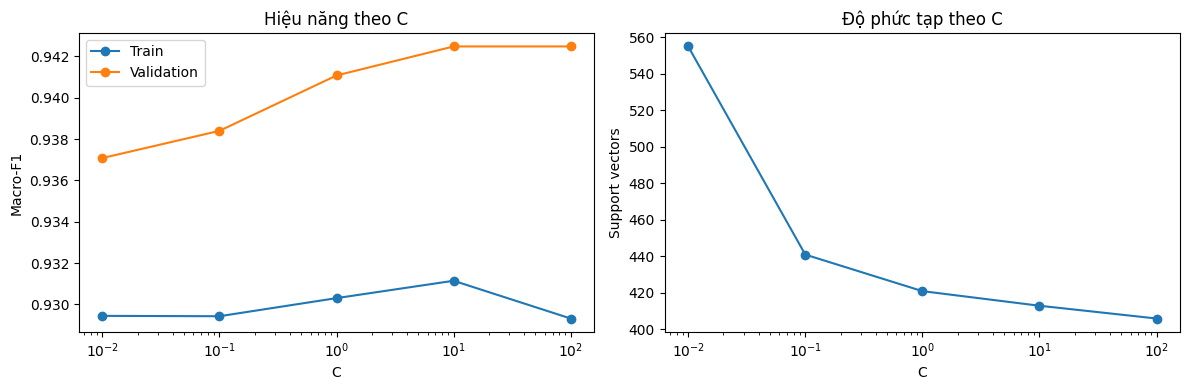

C=0.01: train=0.9294, validation=0.9371, gap=-0.0076, SV=555, margin=1.844
C=0.1: train=0.9294, validation=0.9384, gap=-0.0090, SV=441, margin=1.365
C=1: train=0.9303, validation=0.9411, gap=-0.0108, SV=421, margin=0.753
C=10: train=0.9311, validation=0.9425, gap=-0.0113, SV=413, margin=0.223
C=100: train=0.9293, validation=0.9425, gap=-0.0132, SV=406, margin=0.161
Train và validation cùng thấp gợi ý underfitting; train cao nhưng validation giảm và gap tăng gợi ý overfitting.


In [14]:
# Plot performance (macro-F1) and complexity (support vectors) across C
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].semilogx(linear_results.C, linear_results.train_macro_f1, marker="o", label="Train")
axes[0].semilogx(linear_results.C, linear_results.val_macro_f1, marker="o", label="Validation")
axes[0].set(xlabel="C", ylabel="Macro-F1", title="Hiệu năng theo C")
axes[0].legend()

axes[1].semilogx(linear_results.C, linear_results.support_vectors, marker="o")
axes[1].set(xlabel="C", ylabel="Support vectors", title="Độ phức tạp theo C")
plt.tight_layout(); plt.show()

# Print quantitative breakdown per C value (train vs val gap, SVs, margin)
for row in linear_results.itertuples():
    print(f"C={row.C:g}: train={row.train_macro_f1:.4f}, validation={row.val_macro_f1:.4f}, gap={row.train_macro_f1-row.val_macro_f1:+.4f}, SV={row.support_vectors}, margin={row.margin_width:.3f}")
print("Train và validation cùng thấp gợi ý underfitting; train cao nhưng validation giảm và gap tăng gợi ý overfitting.")

### Nhận xét biểu đồ theo C

Đường validation tăng từ khoảng 0,9371 ở `C=0,01` lên 0,9425 ở `C=10`, rồi gần như không đổi tại `C=100`. Quy tắc chọn ưu tiên `C=10` khi hai điểm gần bằng nhau. Trên cùng grid, số support vectors giảm từ 555 xuống 406 và margin giảm từ khoảng 1,844 xuống 0,161. Validation cao hơn train trong các cấu hình này; kết quả không cho thấy dấu hiệu overfitting rõ theo chênh lệch train–validation.

In [15]:
best = best_row(linear_results, ["C"])
first, last = linear_results.iloc[0], linear_results.iloc[-1]
print(f"Nhận xét: C được chọn theo validation là {best.C:g}, macro-F1 train={best.train_macro_f1:.4f}, validation={best.val_macro_f1:.4f}.")
print(f"Khi C tăng từ {first.C:g} lên {last.C:g}, support vectors thay đổi từ {int(first.support_vectors)} thành {int(last.support_vectors)}, margin từ {first.margin_width:.3f} thành {last.margin_width:.3f}.")
print("Chênh lệch train–validation và thay đổi theo C là dấu hiệu cần xem xét, không đủ để kết luận chắc chắn overfitting từ một split.")

Nhận xét: C được chọn theo validation là 10, macro-F1 train=0.9311, validation=0.9425.
Khi C tăng từ 0.01 lên 100, support vectors thay đổi từ 555 thành 406, margin từ 1.844 thành 0.161.
Chênh lệch train–validation và thay đổi theo C là dấu hiệu cần xem xét, không đủ để kết luận chắc chắn overfitting từ một split.


## Minh họa hai chiều

Dùng `Major_Axis_Length` và `Eccentricity` trên đúng training observations; fit scaler riêng. Chọn `C` bằng validation hai chiều. Minh họa này bổ sung thí nghiệm chính 7 chiều.

### Mục đích của minh họa hai chiều

Chỉ giữ `Major_Axis_Length` và `Eccentricity` để vẽ được hình. Hai lớp và các quan sát train giữ nguyên như bài chính. Scaler hai chiều được fit lại chỉ trên train; `C` cho hình được chọn bằng validation hai chiều. Vì bỏ năm đặc trưng, hình minh họa hình học chứ không đại diện toàn bộ mô hình bảy chiều.

In [16]:
X2_train, X2_val = X_train[PAIR], X_val[PAIR]
scaler2 = StandardScaler().fit(X2_train)
Z2_train, Z2_val = scaler2.transform(X2_train), scaler2.transform(X2_val)
np.testing.assert_allclose(scaler2.mean_, X2_train.mean().to_numpy(), atol=1e-10)

### Chọn C cho minh họa hai chiều

Huấn luyện các ứng viên và đánh giá trên validation hai chiều.

In [17]:
two_d_rows = []

# Search best C on the 2D feature subspace via 2D validation macro-F1
for c in C_GRID:
    candidate = SVC(kernel="linear", C=c).fit(Z2_train, y_train)
    two_d_rows.append({"C": c, "val_macro_f1": metrics(candidate, Z2_val, y_val)["macro_f1"]})
two_d_results = pd.DataFrame(two_d_rows)

# Train optimal 2D Linear SVM with best selected C
two_d_c = float(best_row(two_d_results, ["C"]).C)
model2 = SVC(kernel="linear", C=two_d_c).fit(Z2_train, y_train)
assert list(model2.classes_) == [0, 1]
display(two_d_results.round(4))

,C,val_macro_f1
0,0.01,0.9317
1,0.10,0.9345
2,1.00,0.9358
3,10.00,0.9358
4,100.00,0.9358


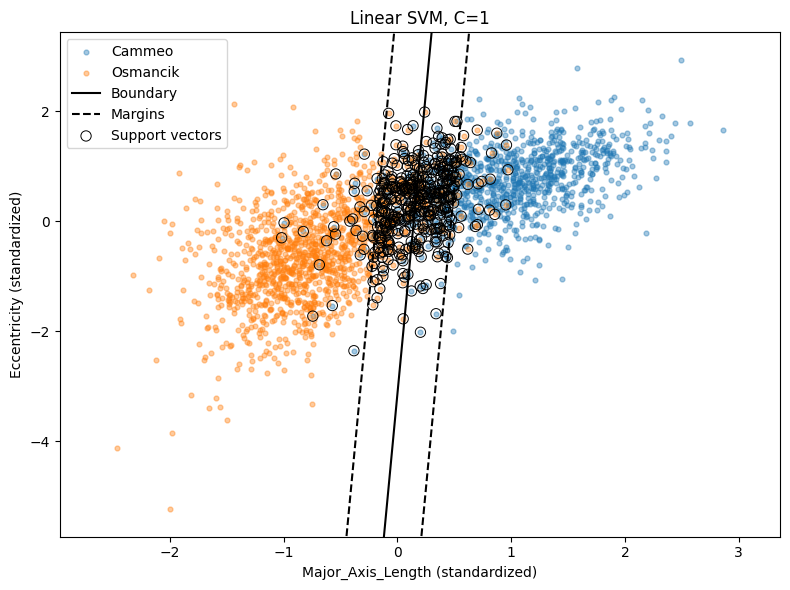

In [18]:
# Extract decision plane parameters: w1*x1 + w2*x2 + b = 0
w, b = model2.coef_[0], float(model2.intercept_[0])
if abs(w[1]) < 1e-12:
    raise ArithmeticError("Second weight too small to draw margin lines")
x_grid = np.linspace(Z2_train[:, 0].min() - 0.5, Z2_train[:, 0].max() + 0.5, 400)

fig, ax = plt.subplots(figsize=(8, 6))

# Plot training observations colored by true rice cultivar
for label, name, color in [(0, "Cammeo", "tab:blue"), (1, "Osmancik", "tab:orange")]:
    mask = y_train.to_numpy() == label
    ax.scatter(Z2_train[mask, 0], Z2_train[mask, 1], s=12, alpha=0.4, c=color, label=name)

# Plot decision boundary (score=0) and margin boundaries (score=+/-1): x2 = (level - b - w1*x1) / w2
for level, style, name in [(0, "-", "Boundary"), (1, "--", "Margins"), (-1, "--", None)]:
    ax.plot(x_grid, (level - b - w[0] * x_grid) / w[1], "k" + style, label=name)

# Highlight active support vectors with hollow circular outlines
ax.scatter(model2.support_vectors_[:, 0], model2.support_vectors_[:, 1], s=55, facecolors="none", edgecolors="black", linewidths=0.7, label="Support vectors")
ax.set(xlabel="Major_Axis_Length (standardized)", ylabel="Eccentricity (standardized)", title=f"Linear SVM, C={two_d_c:g}", xlim=(x_grid.min(), x_grid.max()), ylim=(Z2_train[:, 1].min()-0.5, Z2_train[:, 1].max()+0.5))
ax.legend(); plt.tight_layout(); plt.show()

### Nhận xét hình boundary và margin

Đường liền là biên dự đoán ($w^T x + b = 0$), hai đường đứt là các mức score $-1$ và $+1$; các vòng tròn đánh dấu support vectors.

**Bản chất hình học của bài toán 2D:**
* Hai đặc trưng `Major_Axis_Length` (chiều dài trục chính) và `Eccentricity` (độ lệch tâm elip) phản ánh hình dạng thuôn dài của hạt gạo. Dù giống Cammeo nhìn chung dài hơn và có độ lệch tâm cao hơn Osmancik, phân bố sinh học tự nhiên giữa hai giống vẫn có một dải chồng lấn (overlap) đáng kể ở vùng trung gian.
* Do có sự chồng lấn, bài toán trong không gian 2D là **không thể tách tuyến tính hoàn hảo (non-linearly separable)**: một mô hình hard-margin sẽ không thể hội tụ (vô nghiệm).
* Soft-margin giải quyết bài toán bằng cách chấp nhận các vi phạm có kiểm soát: các mẫu nằm trong dải lề ($0 < \xi_i \le 1$) hoặc bị phân loại sai hẳn sang bên kia đường biên ($\xi_i > 1$) đều trở thành các **bounded support vectors** với $\alpha_i = C$. Lề phân cách tìm được là sự cân bằng tối ưu giữa việc tối đa hóa khoảng cách an toàn và tối thiểu hóa tổng vi phạm.

## NumPy: score, signed distance và hinge loss

Mã hóa `Cammeo=-1`, `Osmancik=+1`; (f(x)=w^Tx+b), (d(x)=f(x)/\|w\|), (L=\max(0,1-yf(x))). Dấu của distance chỉ phía của biên.

### Ý nghĩa các đại lượng

Với tọa độ đã chuẩn hóa, score là `w·x + b`: dấu cho biết phía của đường biên. Signed distance chia score cho `||w||`, tính theo đơn vị tọa độ chuẩn hóa. Hinge loss bằng 0 khi mẫu nằm đúng phía và ở ngoài margin; lớn hơn 0 khi mẫu vi phạm margin. Bảng chọn support vectors và một số điểm dự đoán đúng ngoài tập support để đối chiếu; phép `assert` kiểm tra score với `decision_function`.

In [19]:
labels = y_train.to_numpy()
sv_ids = model2.support_
selected = []

# Select 2 support vectors per class from model support vector index array
for label in [0, 1]:
    candidates = sv_ids[labels[sv_ids] == label]
    assert len(candidates) >= 2
    selected.extend(candidates[:2].tolist())

# Select 1 correctly classified non-support vector per class (outside margin)
non_sv = np.ones(len(labels), dtype=bool)
non_sv[sv_ids] = False
correct = model2.predict(Z2_train) == labels
for label in [0, 1]:
    candidates = np.flatnonzero(non_sv & correct & (labels == label))
    assert len(candidates) > 0
    selected.append(int(candidates[0]))
selected = np.array(selected)

### Tính các đại lượng bằng NumPy

Từ các mẫu đã chọn, tính score, khoảng cách và hinge loss.

In [20]:
# Compute decision scores: f(x) = w^T x + b
decision = Z2_train[selected] @ w + b

# Compute signed geometric distance: d(x) = f(x) / ||w||
distance = decision / np.linalg.norm(w)

# Compute hinge loss with y in {-1, +1}: L = max(0, 1 - y * f(x))
hinge = np.maximum(0, 1 - (2 * labels[selected] - 1) * decision)

# Validate NumPy calculations against scikit-learn decision_function
np.testing.assert_allclose(decision, model2.decision_function(Z2_train[selected]), rtol=1e-10, atol=1e-10)

# Display tabular summary of sampled observations
display(pd.DataFrame({"train_row": selected, "class": [CLASSES[i] for i in labels[selected]], "is_support_vector": np.isin(selected, sv_ids), "decision_score": decision, "signed_distance": distance, "hinge_loss": hinge}).round(5))

,train_row,class,is_support_vector,decision_score,signed_distance,hinge_loss
0,1,Cammeo,True,-0.87350,-0.28742,0.12650
1,32,Cammeo,True,0.11989,0.03945,1.11989
2,18,Osmancik,True,0.82656,0.27197,0.17344
3,30,Osmancik,True,0.16523,0.05437,0.83477
4,2,Cammeo,False,-4.16603,-1.37078,0.00000
5,0,Osmancik,False,2.93164,0.96462,0.00000


### Nhận xét bảng score và hinge loss

Trong bảng đã chạy, mẫu Cammeo ở `train_row=32` có score dương khoảng 0,120: mô hình đặt mẫu về phía Osmancik và hinge loss khoảng 1,120. Hai mẫu không phải support vector trong bảng được phân loại đúng, nằm ngoài margin và có hinge loss bằng 0. Chỉ số `train_row` là vị trí trong tập train sau khi chia, không phải chỉ số dòng gốc của dataset.

## Giải thích lý thuyết chuyên sâu

### 1. Hard margin so với Soft margin
* **Hard margin SVM:** Giả định dữ liệu phân tách tuyến tính hoàn hảo. Yêu cầu mọi điểm huấn luyện phải nằm đúng phía và ở bên ngoài hoặc trên biên lề:
  $$y_i(w^T x_i + b) \ge 1, \quad \forall i=1,\dots,N$$
  Bài toán trở nên vô nghiệm khi dữ liệu có nhiễu hoặc có sự chồng lấn phân bố giữa hai lớp.
* **Soft margin SVM:** Cho phép một số mẫu vi phạm lề bằng cách bổ sung biến bù (slack variable) $\xi_i \ge 0$, tương ứng với hàm tổn thất Hinge Loss $\xi_i = \max(0, 1 - y_i(w^T x_i + b))$. Bài toán tối ưu hóa lồi có dạng:
  $$\min_{w, b, \xi} \frac{1}{2}\|w\|^2 + C \sum_{i=1}^N \xi_i \quad \text{s.t.} \quad y_i(w^T x_i + b) \ge 1 - \xi_i, \; \xi_i \ge 0$$

### 2. Bài toán đối ngẫu (Dual Formulation) và Điều kiện KKT
Bài toán đối ngẫu Lagrange của Soft-margin SVM là:
$$\max_{\alpha} \sum_{i=1}^N \alpha_i - \frac{1}{2} \sum_{i=1}^N \sum_{j=1}^N \alpha_i \alpha_j y_i y_j x_i^T x_j \quad \text{s.t.} \quad 0 \le \alpha_i \le C, \; \sum_{i=1}^N \alpha_i y_i = 0$$
Theo điều kiện bù Karush-Kuhn-Tucker (KKT), nghiệm $(\alpha, \xi)$ phân loại các điểm dữ liệu thành 3 nhóm rõ rệt:
1. **Điểm nằm ngoài lề ($y_i f(x_i) > 1$):** $\xi_i = 0 \implies \alpha_i = 0$. Các điểm này không đóng góp vào vector trọng số $w = \sum_{i=1}^N \alpha_i y_i x_i$.
2. **Điểm nằm chính xác trên đường biên lề ($y_i f(x_i) = 1$):** $\xi_i = 0 \implies 0 < \alpha_i < C$ (**Free support vectors**). Đây là các điểm neo quyết định trực tiếp độ rộng của lề.
3. **Điểm vi phạm lề hoặc phân loại sai ($y_i f(x_i) < 1$):** $\xi_i > 0 \implies \alpha_i = C$ (**Bounded support vectors**). Trọng số đối ngẫu chạm ngưỡng trần $C$.

### 3. Tác động của siêu tham số $C$
* Khi $C$ nhỏ (regularization mạnh): Mô hình ưu tiên tối đa hóa độ rộng lề $\frac{2}{\|w\|}$, sẵn sàng bỏ qua nhiều vi phạm lề (chấp nhận tổng $\sum \xi_i$ lớn). Kết quả là lề rộng, nhưng nhiều điểm rơi vào dải margin và trở thành support vectors.
* Khi $C$ lớn (regularization yếu): Mức phạt vi phạm $C \sum \xi_i$ tăng vọt, buộc bộ tối ưu phải siết chặt lề để loại bỏ các điểm vi phạm. Kết quả là lề hẹp hơn ($2/\|w\|$ giảm), số lượng bounded support vectors giảm, nhưng mô hình nhạy cảm hơn với các điểm nhiễu ngoại lai.

### 4. Vì sao Linear SVM hoạt động rất hiệu quả trên Rice dataset
Trong không gian 7 chiều, các đặc trưng hình thái (diện tích, chu vi, chiều dài trục chính/phụ, độ tròn) có sự đồng biến thiên tự nhiên giữa hai giống lúa. Sự khác biệt về tỷ lệ hình học tạo ra một ranh giới phân tách gần như phẳng giữa hai quần thể hạt, giúp mô hình tuyến tính đơn giản đạt độ chính xác cao mà không cần bổ sung các chiều phi tuyến phức tạp.